# Telco Customer Churn — XGBoost vs. Logistic Regression (SHAP, Gemini explanations, Shiny demo)

**Dataset:** [Telco Customer Churn (Kaggle / IBM)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — `WA_Fn-UseC_-Telco-Customer-Churn.csv` (not included in this repository; the notebook falls back to a public IBM mirror if the file is missing).

**What this notebook does**
- Sections 1–9: setup, cleaning, 60 / 30 / 10 train–test–validation split, feature engineering, and a logistic-regression feature-selection pipeline (p < 0.05, coefficient-sign check against correlation, VIF > 3) that produces a **13-feature** final set.
- Sections 10–13: XGBoost on the same 13 features, decile and ROC analysis, SHAP analysis, full model comparison, threshold selection and final validation.
- Section 14: **Gemini** turns the model output and customer-level SHAP drivers into short business-language explanations. Gemini is used only for narration; it does not change the prediction or the SHAP results.
- Sections 15–18: customer-level SHAP drivers, customer lookup and scoring, a business-facing churn risk dashboard, and what-if scenario analysis.
- Sections 19–21: summary of results, next steps, and the deployment artifacts: `churn_model_bundle.pkl`, `churn_scoring.py` (reusable scoring class), `app.py` (standalone **Shiny for Python** app), and `demo_customer_data.csv`.

**Workflow covered in this notebook**

| # | Section |
|---|------|
| 0 | Setup & imports |
| 1 | Load & clean the data |
| 2 | Train / Test / Validation split (60 / 30 / 10) |
| 3 | Feature engineering (train set, no interaction terms) |
| 4 | Correlation of each feature with churn |
| 5 | Logistic regression — full model (`statsmodels`) |
| 6 | Keep only features with p < 0.05 |
| 7 | Drop features whose coefficient sign disagrees with correlation |
| 8 | VIF test — drop features with VIF > threshold |
| 9 | Finalize logistic regression model → **13 final features**; decile analysis `df1`/`df2`; ROC curve |
| 10 | **XGBoost** model on the same 13 features (train → test) |
| — | Decile analysis — XGBoost train (`df3`) / test (`df4`) |
| 11 | **SHAP** analysis on the XGBoost features |
| 12 | ROC / AUC curve — XGBoost, and Logistic vs. XGBoost overlay |
| 13 | **Model comparison**, threshold selection, and final validation |
| 14 | **Gemini** — customer-level explanation of the model output |
| 15 | SHAP-based **top-3 churn drivers** (global + per-customer) |
| 16 | Customer lookup table, scoring, and explanation |
| 17 | **Business-facing churn risk dashboard** (Shiny app, `app.py`) |
| 18 | **"What-if" scenario analysis** on each selected input |
| 19 | Summary of results |
| 20 | Additional steps to enhance the outputs |
| 21 | **Deployment** — model bundle, scoring module, and Shiny app files |

**To run this notebook (Google Colab):** upload the data file (or let the notebook use the public mirror), then run all cells top to bottom. Section 14 mounts Google Drive and reads a Gemini API key from `/content/drive/MyDrive/api_key.txt`; that file is **never committed** to this repository. Section 14 and the Gemini explanation cell in Section 16 need the key; the rest of the notebook runs without it. Running all cells also writes `churn_scoring.py` and `app.py` and creates the files the Shiny app needs. To serve only the dashboard as a standalone app, run `shiny run app.py --reload` in the same folder after Section 21 has run once (the app does not use the Gemini key).


## 0. Setup & Imports

In [1]:
# If needed:  %pip install xgboost shap scikit-learn pandas matplotlib google-genai shiny joblib
import os, json, warnings, pickle
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score,
                             recall_score, f1_score, accuracy_score,
                             precision_recall_curve, classification_report)
import xgboost as xgb
import shap

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
print("xgboost:", xgb.__version__, "| shap:", shap.__version__)

xgboost: 3.4.1 | shap: 0.52.0


In [2]:
#!pip install google-genai

## 1. Load & Clean the Data

Download `WA_Fn-UseC_-Telco-Customer-Churn.csv` from Kaggle and place it next to this
notebook (or keep the GitHub mirror fallback below — it is the identical IBM source file).

In [3]:
KAGGLE_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
MIRROR_URL  = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
LOCAL_FILE  = "telco_churn.csv"

if os.path.exists(KAGGLE_FILE):
    df = pd.read_csv(KAGGLE_FILE)
elif os.path.exists(LOCAL_FILE):
    df = pd.read_csv(LOCAL_FILE)
else:
    df = pd.read_csv(MIRROR_URL)

# --- basic cleaning -----------------------------------------------------
# TotalCharges is read as string (11 blank rows for brand-new customers)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)          # tenure == 0 rows
# SeniorCitizen: robust to files that store it as 0/1 or as "No"/"Yes"
df["SeniorCitizen"] = df["SeniorCitizen"].replace({0: "No", 1: "Yes", "0": "No", "1": "Yes"}).astype(str)

# Churn: robust encoding — handles "Yes"/"No", "yes ", "True"/"False", 1/0, etc.
if pd.api.types.is_numeric_dtype(df["Churn"]):
    df["Churn"] = (pd.to_numeric(df["Churn"], errors="coerce").fillna(0) > 0).astype(int)
else:
    df["Churn"] = (df["Churn"].astype(str).str.strip().str.lower()
                     .isin(["yes", "true", "1", "y", "churn"])).astype(int)

# Guard: fail early with a clear message instead of a cryptic model error later
assert df["Churn"].nunique() == 2, \
    "Target ended up single-class - inspect the raw Churn column values in your CSV."

print(df.shape)
print("Churn rate: {:.2%}".format(df["Churn"].mean()))
df.head(3)

(7043, 21)
Churn rate: 26.54%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


## 2. Train / Test / Validation Split — 60 / 30 / 10

Stratified on `Churn` so all three partitions keep the same churn rate.

In [4]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

# First carve out 10% validation, then split the remaining 90% into 60/30 (i.e. 2/3 vs 1/3)
X_tmp, X_val, y_tmp, y_val = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X_tmp, y_tmp, test_size=30/90, stratify=y_tmp, random_state=RANDOM_STATE)

for name, part_y in [("Train", y_train), ("Test", y_test), ("Val", y_val)]:
    print(f"{name:5s}: n={len(part_y):5d} ({len(part_y)/len(y):.0%})  churn={part_y.mean():.2%}")

Train: n= 4225 (60%)  churn=26.53%
Test : n= 2113 (30%)  churn=26.55%
Val  : n=  705 (10%)  churn=26.52%


In [5]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 3. Feature Engineering (Train Set) — No Interaction Terms

All transformations below are single-column (no products/interactions between features):

- **Binary yes/no + gender** mapped to 0/1.
- **"No phone/internet service" categories collapsed into "No"** for the six add-on service
  columns and `MultipleLines`, since that state is already fully captured by `PhoneService` /
  `InternetService`. Keeping a separate dummy for it would just duplicate that information and
  cause perfect collinearity later.
- **Derived single-feature variables:** `AvgMonthlySpend` (TotalCharges / tenure), `IsNewCustomer`
  (tenure ≤ 6 months flag), `NumServices` (count of add-on services subscribed to).
- **One-hot encoding** (`drop_first=True`) for the remaining multi-category columns:
  `InternetService`, `Contract`, `PaymentMethod`.

The same encoder logic (fit conceptually on train) is applied to the test set, with columns
re-aligned so both frames have an identical feature set.

In [6]:
def engineer_features(X_part):
    """Single-column feature engineering only — no interaction/product terms."""
    d = X_part.copy()
    d = d.drop(columns=["customerID"])

    binary_map = {"Yes": 1, "No": 0, "Female": 1, "Male": 0}
    for c in ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
        d[c] = d[c].map(binary_map)

    # Collapse "No phone/internet service" into "No" — already captured by
    # PhoneService / InternetService, so a separate flag here would just be a
    # perfectly-collinear duplicate.
    d["MultipleLines"] = d["MultipleLines"].replace({"No phone service": "No"})
    service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                     "TechSupport", "StreamingTV", "StreamingMovies"]
    for c in service_cols:
        d[c] = d[c].replace({"No internet service": "No"})

    # Derived single-feature variables (no interaction terms)
    d["AvgMonthlySpend"] = d["TotalCharges"] / d["tenure"].replace(0, 1)
    d["IsNewCustomer"] = (d["tenure"] <= 6).astype(int)
    d["NumServices"] = sum((d[c] == "Yes").astype(int) for c in service_cols)

    for c in ["MultipleLines"] + service_cols:
        d[c] = d[c].map(binary_map)

    multicat_cols = ["InternetService", "Contract", "PaymentMethod"]
    d = pd.get_dummies(d, columns=multicat_cols, drop_first=True)

    bool_cols = d.select_dtypes(bool).columns
    d[bool_cols] = d[bool_cols].astype(int)
    return d

X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)
X_test_fe = X_test_fe.reindex(columns=X_train_fe.columns, fill_value=0)  # keep test columns aligned to train

print("Train engineered shape:", X_train_fe.shape)
print("Test  engineered shape:", X_test_fe.shape)
print("\nEngineered features:")
print(X_train_fe.columns.tolist())
X_train_fe.head(3)

Train engineered shape: (4225, 26)
Test  engineered shape: (2113, 26)

Engineered features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend', 'IsNewCustomer', 'NumServices', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,AvgMonthlySpend,IsNewCustomer,NumServices,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
5944,0,0,0,0,12,1,0,1,0,0,1,0,0,0,56.65,654.85,54.570833,0,2,0,0,0,0,0,0,1
6712,0,0,1,1,28,1,0,0,0,1,0,1,0,0,85.45,2289.90,81.782143,0,2,1,0,0,0,0,1,0
2612,1,0,1,1,14,1,1,0,1,0,1,1,1,0,80.45,1137.05,81.217857,0,4,0,0,0,0,1,0,0


## 4. Correlation of Each Feature with Churn (Train Set)

Simple Pearson correlation of every engineered feature against the `Churn` target. This gives an
independent, univariate read on each feature's directional relationship with churn, which is used
later (Step 5) as a sanity check on the regression coefficients' signs.

=== Correlation of each feature with Churn (train) ===
tenure                                  -0.345842
InternetService_Fiber optic              0.319035
PaymentMethod_Electronic check           0.317460
Contract_Two year                       -0.300051
IsNewCustomer                            0.298234
InternetService_No                      -0.234327
AvgMonthlySpend                          0.206011
MonthlyCharges                           0.205632
PaperlessBilling                         0.198422
TotalCharges                            -0.190757
OnlineSecurity                          -0.176949
Contract_One year                       -0.176211
TechSupport                             -0.160823
Dependents                              -0.160482
SeniorCitizen                            0.153900
Partner                                 -0.146528
PaymentMethod_Credit card (automatic)   -0.135606
PaymentMethod_Mailed check              -0.090105
OnlineBackup                            -0.07

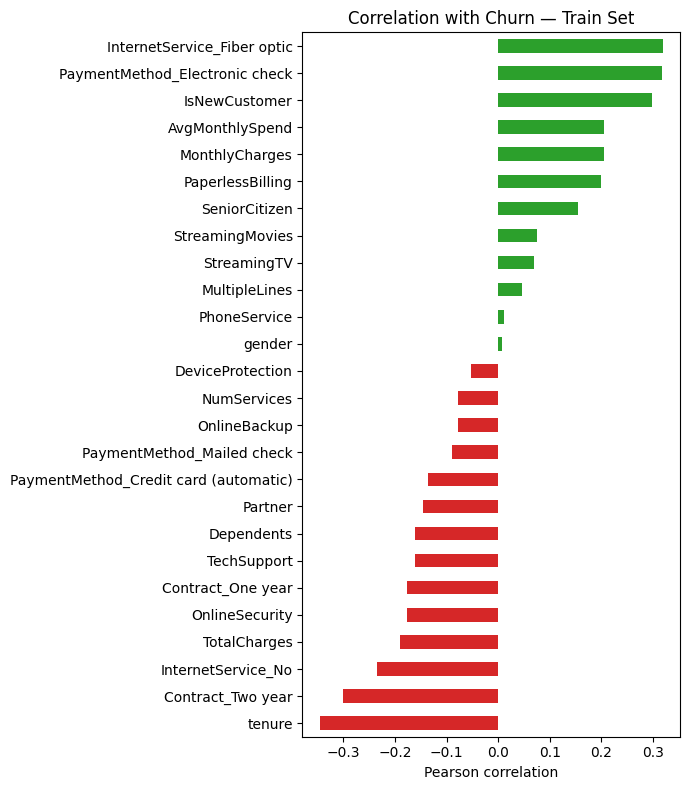

In [7]:
train_fe_with_target = X_train_fe.copy()
train_fe_with_target["Churn"] = y_train.values

corr_with_churn = (train_fe_with_target.corr(numeric_only=True)["Churn"]
                    .drop("Churn")
                    .sort_values(key=abs, ascending=False))

print("=== Correlation of each feature with Churn (train) ===")
print(corr_with_churn.to_string())

fig, ax = plt.subplots(figsize=(7, 8))
corr_with_churn.sort_values().plot(kind="barh", ax=ax,
                                    color=["#d62728" if v < 0 else "#2ca02c" for v in corr_with_churn.sort_values()])
ax.set_title("Correlation with Churn — Train Set")
ax.set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

## 5. Logistic Regression — `statsmodels`

Fit a full logistic regression (`statsmodels.api.Logit`) on every engineered feature from the
train set, with a constant term. This is the baseline model that the following steps will prune.

In [8]:
Xtr_full = sm.add_constant(X_train_fe.astype(float))
ytr = y_train.astype(float).values

full_model = sm.Logit(ytr, Xtr_full).fit(disp=0)
print(full_model.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 4225
Model:                          Logit   Df Residuals:                     4199
Method:                           MLE   Df Model:                           25
Date:                Thu, 17 Sep 2026   Pseudo R-squ.:                  0.2932
Time:                        18:18:22   Log-Likelihood:                -1727.8
converged:                       True   LL-Null:                       -2444.4
Covariance Type:            nonrobust   LLR p-value:                3.149e-287
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                     0.4341      1.070      0.406      0.685      -1.663       2.531
gender                                   -0.0349  

## 6. Keep Only Features with p < 0.05

Backward elimination: repeatedly refit the model and drop the single feature with the highest
p-value, until every remaining feature (excluding the constant) is significant at the 5% level.

In [9]:
def backward_elim_pvalue(X_design, y_arr, alpha=0.05):
    X_cur = X_design.copy()
    while True:
        m = sm.Logit(y_arr, X_cur).fit(disp=0)
        pvals = m.pvalues.drop("const", errors="ignore")
        if len(pvals) == 0:
            return m, X_cur
        worst_feat = pvals.idxmax()
        if pvals[worst_feat] < alpha:
            return m, X_cur
        X_cur = X_cur.drop(columns=[worst_feat])

model_p, X_p = backward_elim_pvalue(Xtr_full, ytr, alpha=0.05)

print("=== Model after p<0.05 backward elimination ===")
print(model_p.summary())
print("\nRemaining features ({}):".format(len(X_p.columns) - 1))
print([c for c in X_p.columns if c != "const"])

=== Model after p<0.05 backward elimination ===
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 4225
Model:                          Logit   Df Residuals:                     4210
Method:                           MLE   Df Model:                           14
Date:                Thu, 17 Sep 2026   Pseudo R-squ.:                  0.2916
Time:                        18:18:23   Log-Likelihood:                -1731.5
converged:                       True   LL-Null:                       -2444.4
Covariance Type:            nonrobust   LLR p-value:                4.687e-296
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -0.2740      0.308     -0.888      0.374      -0.879       0.331
SeniorCitizen          

## 7. Remove Features Whose Coefficient Sign Disagrees with the Step-2 Correlation

For each remaining feature, compare the sign of its regression coefficient to the sign of its
univariate correlation with `Churn` from Step 2. If they disagree, the feature's relationship
with churn is not stable/interpretable in the presence of the other predictors, so it's dropped
(one at a time, refitting — and re-running the p<0.05 filter — after each removal, since dropping
a feature can change the significance of the others).

In [10]:
def sign_filter(model_in, X_in, y_arr, corr_series, alpha=0.05):
    m, X_cur = model_in, X_in
    while True:
        coefs = m.params.drop("const", errors="ignore")
        mismatches = [f for f in coefs.index if np.sign(coefs[f]) != np.sign(corr_series.get(f, 0.0))]
        if not mismatches:
            return m, X_cur
        drop_feat = max(mismatches, key=lambda f: abs(coefs[f]))
        print(f"Dropping '{drop_feat}' — coef sign {np.sign(coefs[drop_feat]):+.0f} "
              f"vs. correlation sign {np.sign(corr_series.get(drop_feat, 0.0)):+.0f}")
        X_cur = X_cur.drop(columns=[drop_feat])
        m, X_cur = backward_elim_pvalue(X_cur, y_arr, alpha=alpha)

model_s, X_s = sign_filter(model_p, X_p, ytr, corr_with_churn)

print("\n=== Model after sign-match filtering ===")
print(model_s.summary())
print("\nRemaining features ({}):".format(len(X_s.columns) - 1))
print([c for c in X_s.columns if c != "const"])

Dropping 'MonthlyCharges' — coef sign -1 vs. correlation sign +1

=== Model after sign-match filtering ===
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 4225
Model:                          Logit   Df Residuals:                     4211
Method:                           MLE   Df Model:                           13
Date:                Thu, 17 Sep 2026   Pseudo R-squ.:                  0.2888
Time:                        18:18:23   Log-Likelihood:                -1738.4
converged:                       True   LL-Null:                       -2444.4
Covariance Type:            nonrobust   LLR p-value:                3.874e-294
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -1.3001      0.142     -9.159

## 8. VIF Test — Remove Features with VIF > 3

Compute the Variance Inflation Factor for every remaining feature and drop the single worst
offender above the threshold of 3, refitting (and re-applying the p<0.05 and sign-match checks)
after each removal, until every feature's VIF is at or below 3.

In [11]:
def vif_filter(X_in, y_arr, corr_series, threshold=5.0):
    feats = [c for c in X_in.columns if c != "const"]
    X_cur = X_in.copy()
    last_vif_table = None
    while len(feats) > 1:
        vif_vals = [variance_inflation_factor(X_cur[["const"] + feats].values, i + 1)
                    for i in range(len(feats))]
        vif_df = pd.DataFrame({"feature": feats, "VIF": vif_vals}).sort_values("VIF", ascending=False)
        last_vif_table = vif_df
        if vif_df["VIF"].max() <= threshold:
            break
        drop_feat = vif_df.iloc[0]["feature"]
        print(f"Dropping '{drop_feat}' — VIF = {vif_df.iloc[0]['VIF']:.2f}")
        feats.remove(drop_feat)
        X_cur = X_cur[["const"] + feats]
        # re-fit and re-check p-values & sign after removing a feature
        m, X_cur = backward_elim_pvalue(X_cur, y_arr)
        m, X_cur = sign_filter(m, X_cur, y_arr, corr_series)
        feats = [c for c in X_cur.columns if c != "const"]
    m, X_cur = backward_elim_pvalue(X_cur[["const"] + feats], y_arr)
    m, X_cur = sign_filter(m, X_cur, y_arr, corr_series)
    return m, X_cur, last_vif_table

model_v, X_v, final_vif_table = vif_filter(X_s, ytr, corr_with_churn, threshold=5.0)

print("\n=== Final VIF table ===")
print(final_vif_table.to_string(index=False))
print("\n=== Model after VIF filtering (VIF <= 5 for all features) ===")
print(model_v.summary())


=== Final VIF table ===
                       feature      VIF
                        tenure 3.005673
             Contract_Two year 2.505284
            InternetService_No 2.019799
                 IsNewCustomer 1.716554
   InternetService_Fiber optic 1.709311
             Contract_One year 1.635313
               StreamingMovies 1.567562
                   StreamingTV 1.556838
                OnlineSecurity 1.410444
                 MultipleLines 1.345689
PaymentMethod_Electronic check 1.308136
              PaperlessBilling 1.194519
                 SeniorCitizen 1.112900

=== Model after VIF filtering (VIF <= 5 for all features) ===
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 4225
Model:                          Logit   Df Residuals:                     4211
Method:                           MLE   Df Model:                           13
Date:                Thu, 17 Sep 202

## 9. Finalize the Regression Model & Validate on the Test Set

The surviving features from Step 8 form the final model. Refit one more time on the full train
set with just these features (for clean, final coefficients), then score both train and test.

In [12]:
final_features = [c for c in X_v.columns if c != "const"]
print(f"Final feature set ({len(final_features)} features):")
print(final_features)

Xtr_final = X_v[["const"] + final_features]
final_model = sm.Logit(ytr, Xtr_final).fit(disp=0)
print("\n=== FINAL logistic regression model ===")
print(final_model.summary())

# Build the matching test-set design matrix (same columns/order as train)
Xte_final = sm.add_constant(X_test_fe.astype(float), has_constant="add")
Xte_final = Xte_final[["const"] + final_features]

train_pred = final_model.predict(Xtr_final)
test_pred = final_model.predict(Xte_final)

auc_train = roc_auc_score(ytr, train_pred)
auc_test = roc_auc_score(y_test.values, test_pred)

print(f"\nTrain AUC: {auc_train:.4f}")
print(f"Test  AUC: {auc_test:.4f}")

for thresh in [0.5]:
    test_class = (test_pred >= thresh).astype(int)
    print(f"\n--- Test-set classification report @ threshold {thresh} ---")
    print(classification_report(y_test.values, test_class, digits=3))

Final feature set (13 features):
['SeniorCitizen', 'tenure', 'MultipleLines', 'OnlineSecurity', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'IsNewCustomer', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Electronic check']

=== FINAL logistic regression model ===
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 4225
Model:                          Logit   Df Residuals:                     4211
Method:                           MLE   Df Model:                           13
Date:                Thu, 17 Sep 2026   Pseudo R-squ.:                  0.2888
Time:                        18:18:24   Log-Likelihood:                -1738.4
converged:                       True   LL-Null:                       -2444.4
Covariance Type:            nonrobust   LLR p-value:                3.874e-294
                               

## Decile Analysis — Train (`df1`) and Test (`df2`)

Customers are ranked by predicted churn probability and split into 10 equal-sized deciles
(decile 1 = highest predicted risk). A well-performing model should show churn rate and lift
decreasing monotonically from decile 1 to decile 10.

In [13]:
def decile_analysis(y_true, y_score, n=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "score": np.asarray(y_score)})
    # rank so that decile 1 = highest predicted probability of churn
    d["decile"] = n - pd.qcut(d["score"].rank(method="first"), n, labels=False)
    g = (d.groupby("decile")
           .agg(n_customers=("y", "size"), churners=("y", "sum"), avg_predicted_prob=("score", "mean"))
           .sort_index())
    g["actual_churn_rate"] = g["churners"] / g["n_customers"]
    g["cum_churners"] = g["churners"].cumsum()
    g["cum_pct_of_all_churners"] = g["cum_churners"] / g["churners"].sum()
    g["lift"] = g["actual_churn_rate"] / d["y"].mean()
    return g.round(4)

df1 = decile_analysis(ytr, train_pred.values)          # train
df2 = decile_analysis(y_test.values, test_pred.values)  # test

print("=== df1 — Train decile analysis ===")
display(df1)

print("\n=== df2 — Test decile analysis ===")
display(df2)

=== df1 — Train decile analysis ===


,n_customers,churners,avg_predicted_prob,actual_churn_rate,cum_churners,cum_pct_of_all_churners,lift
decile,,,,,,,
1,423,326.0,0.7602,0.7707,326.0,0.2908,2.9047
2,422,248.0,0.5861,0.5877,574.0,0.5120,2.2149
3,423,185.0,0.4452,0.4374,759.0,0.6771,1.6484
4,422,122.0,0.3211,0.2891,881.0,0.7859,1.0896
5,422,110.0,0.2231,0.2607,991.0,0.8840,0.9824
6,423,58.0,0.1536,0.1371,1049.0,0.9358,0.5168
7,422,41.0,0.0867,0.0972,1090.0,0.9723,0.3662
8,423,18.0,0.0455,0.0426,1108.0,0.9884,0.1604
9,422,10.0,0.0227,0.0237,1118.0,0.9973,0.0893



=== df2 — Test decile analysis ===


,n_customers,churners,avg_predicted_prob,actual_churn_rate,cum_churners,cum_pct_of_all_churners,lift
decile,,,,,,,
1,212,153,0.7530,0.7217,153,0.2727,2.7183
2,211,132,0.5843,0.6256,285,0.5080,2.3563
3,211,94,0.4593,0.4455,379,0.6756,1.6780
4,211,65,0.3407,0.3081,444,0.7914,1.1603
5,211,45,0.2344,0.2133,489,0.8717,0.8033
6,212,35,0.1555,0.1651,524,0.9340,0.6218
7,211,19,0.0928,0.0900,543,0.9679,0.3392
8,211,11,0.0526,0.0521,554,0.9875,0.1964
9,211,5,0.0258,0.0237,559,0.9964,0.0893


## ROC / AUC Curves — Train vs. Test

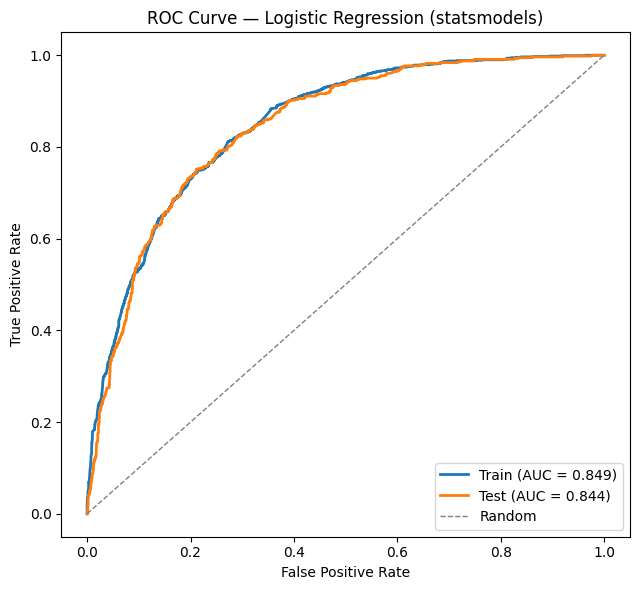

In [14]:
fpr_tr, tpr_tr, _ = roc_curve(ytr, train_pred)
fpr_te, tpr_te, _ = roc_curve(y_test.values, test_pred)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr_tr, tpr_tr, label=f"Train (AUC = {auc_train:.3f})", color="#1f77b4", lw=2)
ax.plot(fpr_te, tpr_te, label=f"Test (AUC = {auc_test:.3f})", color="#ff7f0e", lw=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1, label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Logistic Regression (statsmodels)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. XGBoost — Same 13 Selected Features

Train an XGBoost classifier using the same 13 predictors selected by the
Logistic Regression feature-selection workflow.

Using the same feature set allows a direct comparison between the interpretable
Logistic Regression baseline and a nonlinear tree-based model.

In [15]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report

# Same 13 features selected by Logistic Regression
X_train_xgb = X_train_fe[final_features].astype(float)
X_test_xgb = X_test_fe[final_features].astype(float)

y_train_xgb = y_train.astype(int)
y_test_xgb = y_test.astype(int)

# Keep the search intentionally small for this dataset
param_grid = {
    "n_estimators": [25, 50, 75, 100],
    "learning_rate": [0.01, 0.03, 0.05, 0.10]
}

base_xgb = XGBClassifier(
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train_xgb, y_train_xgb)

xgb_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print(f"Best CV AUC: {grid_search.best_score_:.4f}")

# Probability predictions
xgb_train_prob = xgb_model.predict_proba(X_train_xgb)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test_xgb)[:, 1]

# AUC
xgb_train_auc = roc_auc_score(y_train_xgb, xgb_train_prob)
xgb_test_auc = roc_auc_score(y_test_xgb, xgb_test_prob)

print(f"\nTrain AUC: {xgb_train_auc:.4f}")
print(f"Test  AUC: {xgb_test_auc:.4f}")

# Classification at the same 0.5 threshold used by Logistic Regression
threshold = 0.5
xgb_test_pred = (xgb_test_prob >= threshold).astype(int)

print("\n--- Test-set classification report @ threshold 0.5 ---")
print(classification_report(y_test_xgb, xgb_test_pred, digits=3))

Best parameters: {'learning_rate': 0.05, 'n_estimators': 100}
Best CV AUC: 0.8474

Train AUC: 0.8604
Test  AUC: 0.8460

--- Test-set classification report @ threshold 0.5 ---
              precision    recall  f1-score   support

           0      0.837     0.907     0.871      1552
           1      0.666     0.512     0.579       561

    accuracy                          0.802      2113
   macro avg      0.751     0.709     0.725      2113
weighted avg      0.792     0.802     0.793      2113



## Decile Analysis — Train (`df3`) and Test (`df4`)

Evaluate how well the XGBoost model concentrates churn risk across predicted-probability deciles,
using the same analysis framework as the Logistic Regression model.

In [16]:
df3 = decile_analysis(y_train_xgb, xgb_train_prob)   # XGBoost train
df4 = decile_analysis(y_test_xgb, xgb_test_prob)     # XGBoost test

print("=== df3 — XGBoost Train decile analysis ===")
display(df3)

print("\n=== df4 — XGBoost Test decile analysis ===")
display(df4)

=== df3 — XGBoost Train decile analysis ===


,n_customers,churners,avg_predicted_prob,actual_churn_rate,cum_churners,cum_pct_of_all_churners,lift
decile,,,,,,,
1,423,340,0.7462,0.8038,340,0.3033,3.0294
2,422,249,0.5648,0.5900,589,0.5254,2.2239
3,423,176,0.4344,0.4161,765,0.6824,1.5682
4,422,141,0.3229,0.3341,906,0.8082,1.2593
5,422,97,0.2341,0.2299,1003,0.8947,0.8663
6,423,53,0.1491,0.1253,1056,0.9420,0.4722
7,422,42,0.0973,0.0995,1098,0.9795,0.3751
8,423,14,0.0541,0.0331,1112,0.9920,0.1247
9,422,6,0.0301,0.0142,1118,0.9973,0.0536



=== df4 — XGBoost Test decile analysis ===


,n_customers,churners,avg_predicted_prob,actual_churn_rate,cum_churners,cum_pct_of_all_churners,lift
decile,,,,,,,
1,212,155,0.7400,0.7311,155,0.2763,2.7538
2,211,124,0.5681,0.5877,279,0.4973,2.2135
3,211,100,0.4454,0.4739,379,0.6756,1.7851
4,211,66,0.3381,0.3128,445,0.7932,1.1781
5,211,53,0.2465,0.2512,498,0.8877,0.9461
6,212,23,0.1562,0.1085,521,0.9287,0.4086
7,211,23,0.1002,0.1090,544,0.9697,0.4106
8,211,10,0.0609,0.0474,554,0.9875,0.1785
9,211,5,0.0331,0.0237,559,0.9964,0.0893


## 11. SHAP Analysis on the XGBoost Model

Use SHAP to interpret the final tuned XGBoost model and evaluate how the 13 selected predictors contribute to churn predictions.

The analysis includes:
- Global feature importance based on mean absolute SHAP values.
- SHAP summary plot to show both feature importance and the direction of feature effects.
- Test-set observations are used for interpretation.

In [17]:
explainer = shap.Explainer(xgb_model)
shap_values = explainer(X_test_xgb)

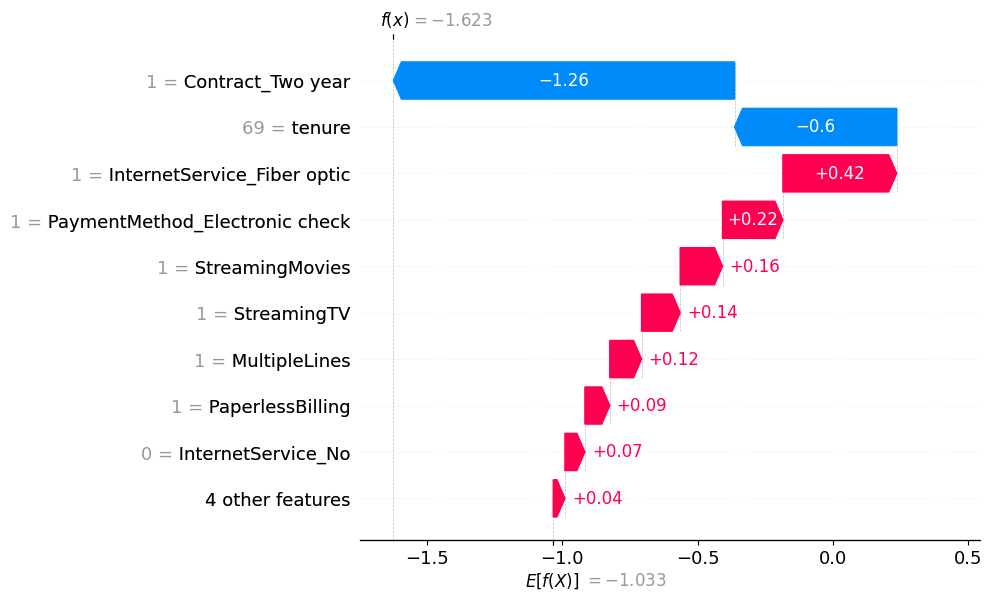

In [18]:
# visualize the first prediction's explanation
shap.plots.waterfall(shap_values[0])

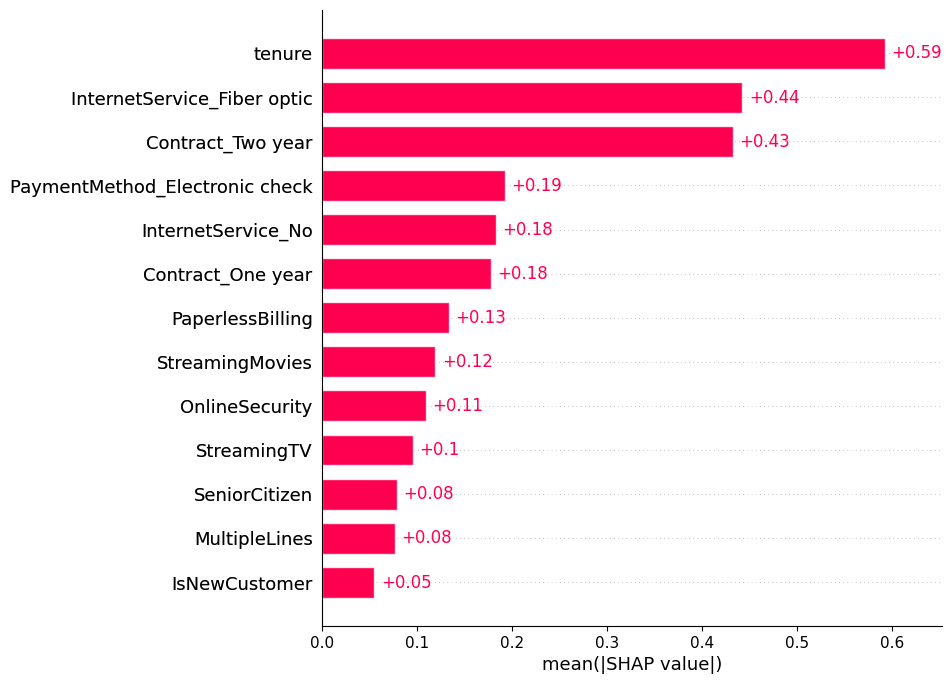

In [19]:
# Global feature importance ranking
shap.plots.bar(shap_values, max_display=13)

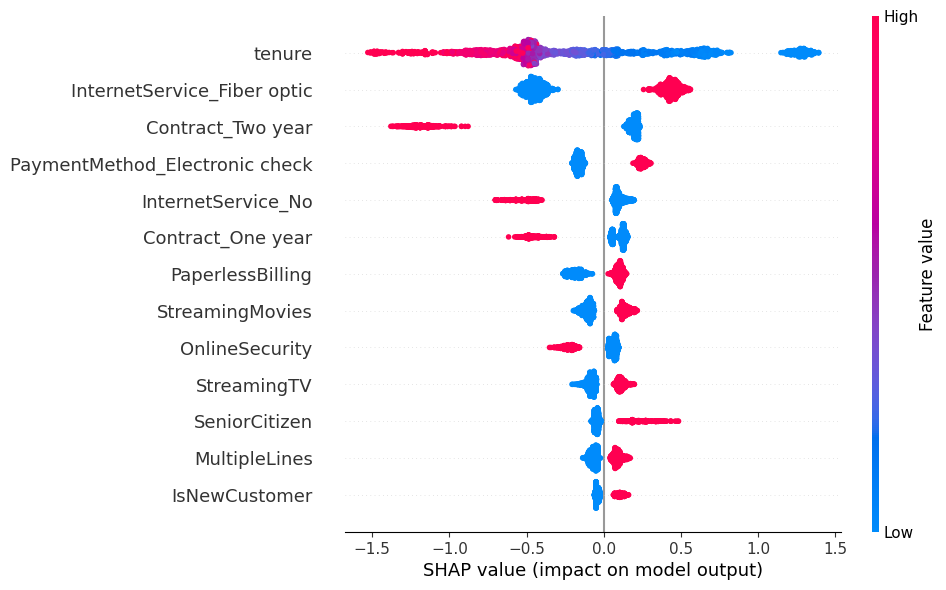

In [20]:
# Global importance + direction
shap.plots.beeswarm(shap_values, max_display=13)

## 12. ROC/AUC curves — XGBoost, and a Logistic-vs-XGBoost overlay

Evaluate the discrimination performance of the tuned XGBoost model and compare it with the Logistic Regression baseline using ROC curves and AUC on the test set.

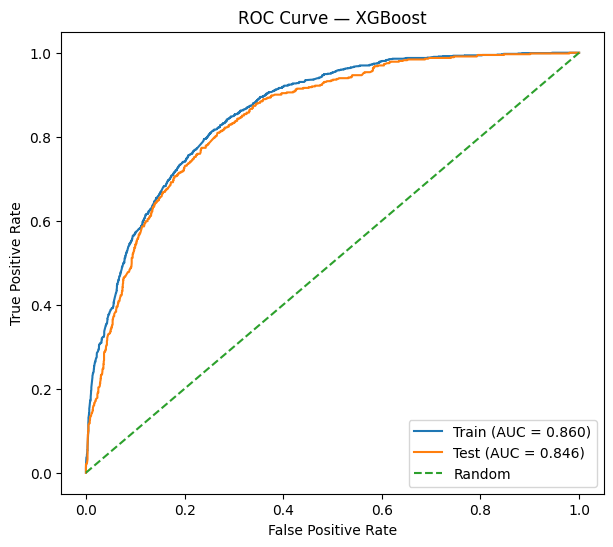

In [21]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# XGBoost ROC curves
fpr_train_xgb, tpr_train_xgb, _ = roc_curve(y_train_xgb, xgb_train_prob)
fpr_test_xgb, tpr_test_xgb, _ = roc_curve(y_test_xgb, xgb_test_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr_train_xgb,tpr_train_xgb,label=f"Train (AUC = {xgb_train_auc:.3f})")
plt.plot(fpr_test_xgb,tpr_test_xgb,label=f"Test (AUC = {xgb_test_auc:.3f})")
plt.plot([0, 1],[0, 1],"--",label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — XGBoost")
plt.legend()
plt.show()

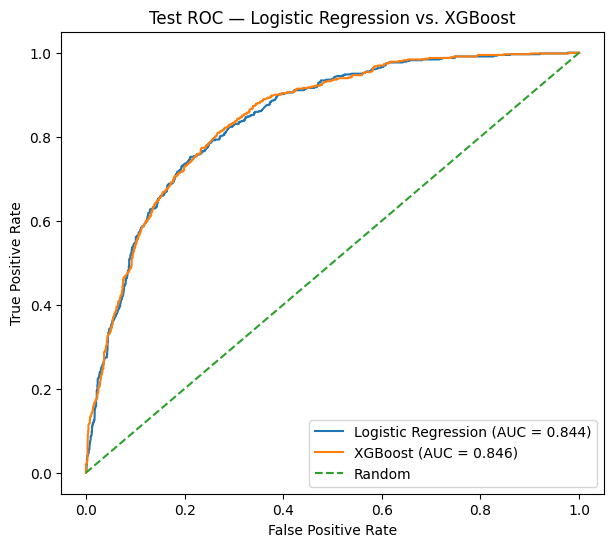

In [22]:
# Logistic Regression test ROC
fpr_logit, tpr_logit, _ = roc_curve(y_test.values,test_pred.values)

# XGBoost test ROC
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_xgb,xgb_test_prob)

plt.figure(figsize=(7, 6))

plt.plot(fpr_logit,tpr_logit,label=f"Logistic Regression (AUC = {auc_test:.3f})")

plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {xgb_test_auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC — Logistic Regression vs. XGBoost")
plt.legend()
plt.show()

The tuned XGBoost model shows stable generalization, with Train AUC = 0.860 and Test AUC = 0.846.

On the test set, XGBoost only marginally outperforms Logistic Regression in ROC-AUC (0.846 vs. 0.844). The highly overlapping ROC curves indicate that the two models have very similar overall discrimination performance.

## 13. Full Model Comparison, Threshold Selection, and Final Validation

Logistic Regression and XGBoost are compared using the same 13 predictors.

Model-specific classification thresholds are selected by maximizing F1 score on 5-fold out-of-fold training predictions. After the thresholds are locked, both models are evaluated on the test set and then confirmed once on the untouched validation set.


In [23]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
X_train_final = X_train_fe[final_features].astype(float)
X_test_final = X_test_fe[final_features].astype(float)
y_train_final = y_train.astype(int)
y_test_final = y_test.astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Logistic Regression OOF probabilities
logit_oof_prob = np.zeros(len(y_train_final))

for train_idx, val_idx in cv.split(X_train_final, y_train_final):
    X_fold_train = sm.add_constant(X_train_final.iloc[train_idx], has_constant="add")
    X_fold_val = sm.add_constant(X_train_final.iloc[val_idx], has_constant="add")
    fold_model = sm.Logit(y_train_final.iloc[train_idx], X_fold_train).fit(disp=False)
    logit_oof_prob[val_idx] = fold_model.predict(X_fold_val)

# XGBoost OOF probabilities
xgb_oof_prob = cross_val_predict(
    xgb_model, X_train_final, y_train_final,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

def select_threshold(y_true, y_prob):
    rows = []
    for threshold in np.arange(0.10, 0.71, 0.02):
        pred = (y_prob >= threshold).astype(int)
        rows.append({
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred)
        })
    results = pd.DataFrame(rows)
    return results.loc[results["F1"].idxmax()]

logit_best = select_threshold(y_train_final, logit_oof_prob)
xgb_best = select_threshold(y_train_final, xgb_oof_prob)

logit_threshold = float(logit_best["Threshold"])
xgb_threshold = float(xgb_best["Threshold"])

selected_thresholds = pd.DataFrame({
    "Model": ["Logistic Regression", "XGBoost"],
    "Threshold": [logit_threshold, xgb_threshold],
    "OOF F1": [logit_best["F1"], xgb_best["F1"]]
})

selected_thresholds.round(4)

,Model,Threshold,OOF F1
0,Logistic Regression,0.32,0.6326
1,XGBoost,0.34,0.6335


In [24]:
# Untouched validation set
X_val_fe = engineer_features(X_val)
X_val_fe = X_val_fe.reindex(columns=X_train_fe.columns, fill_value=0)
X_val_final = X_val_fe[final_features].astype(float)
y_val_final = y_val.astype(int)

# Test probabilities
logit_test_prob = np.asarray(test_pred)
xgb_test_prob = np.asarray(xgb_test_prob)

# Validation probabilities
X_val_logit = sm.add_constant(X_val_final, has_constant="add")
X_val_logit = X_val_logit[["const"] + final_features]

logit_val_prob = np.asarray(final_model.predict(X_val_logit))
xgb_val_prob = xgb_model.predict_proba(X_val_final)[:, 1]

def evaluate_model(dataset, model, y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Dataset": dataset,
        "Model": model,
        "Threshold": threshold,
        "AUC": roc_auc_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

model_confirmation = pd.DataFrame([
    evaluate_model("Test", "Logistic Regression", y_test_final, logit_test_prob, logit_threshold),
    evaluate_model("Test", "XGBoost", y_test_final, xgb_test_prob, xgb_threshold),
    evaluate_model("Validation", "Logistic Regression", y_val_final, logit_val_prob, logit_threshold),
    evaluate_model("Validation", "XGBoost", y_val_final, xgb_val_prob, xgb_threshold)
])

model_confirmation.round(4)

,Dataset,Model,Threshold,AUC,Accuracy,Precision,Recall,F1
0,Test,Logistic Regression,0.32,0.8438,0.7667,0.5435,0.7576,0.6329
1,Test,XGBoost,0.34,0.8460,0.7780,0.5628,0.7344,0.6373
2,Validation,Logistic Regression,0.32,0.8566,0.7759,0.5597,0.7273,0.6326
3,Validation,XGBoost,0.34,0.8561,0.7716,0.5537,0.7166,0.6247


## 14. Gemini-Based Customer-Level Explanation

Use Gemini to translate XGBoost predictions and customer-level SHAP contributions into concise, business-friendly explanations.

XGBoost generates the churn probability and classification, SHAP identifies the factors pushing the prediction higher or lower, and Gemini converts these results into natural-language explanations. Gemini is used only for narration and does not modify the model prediction or SHAP results.

In [25]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [26]:
from google import genai

with open("/content/drive/MyDrive/api_key.txt", "r") as f:
    GEMINI_API_KEY = f.read().strip()

client = genai.Client(api_key=GEMINI_API_KEY)
GEMINI_MODEL = "gemini-3.5-flash"

In [27]:
def generate_customer_explanation(customer_id, churn_prob, threshold, pred_label, churn_drivers, protective_drivers):
    prompt = f"""
You are explaining a customer churn model prediction to a business user.

Customer ID: {customer_id}
Predicted churn probability: {churn_prob:.3f}
Decision threshold: {threshold:.2f}
Predicted class: {pred_label}

Top SHAP-based factors pushing the prediction toward higher churn risk:
{churn_drivers.to_string(index=False)}

Top SHAP-based factors pushing the prediction toward lower churn risk:
{protective_drivers.to_string(index=False)}

Using only the model evidence above:

1. Briefly summarize the customer's predicted churn risk.
2. Explain the main factors pushing the model prediction toward higher churn risk.
3. Explain the main factors pushing the model prediction toward lower churn risk.
4. Explain whether the strongest SHAP contributions overall push the model prediction toward higher or lower churn risk.

Rules:
- Treat SHAP values as model-output contributions, not as percentage-point changes in churn probability.
- Do not sum SHAP values or compare summed positive and negative SHAP values.
- Do not imply that SHAP values directly translate into changes in churn probability.
- Do not make causal claims.
- Do not infer units, customer characteristics, or business meanings that are not explicitly provided.
- Do not introduce information not provided above.
- Do not change or independently reinterpret the XGBoost prediction, decision threshold, or SHAP results.
- Use the predicted churn probability and decision threshold only to explain the final predicted class.
- Use concise, business-friendly language.
"""
    response = client.models.generate_content(model=GEMINI_MODEL, contents=prompt)
    return response.text

## 15. Customer-Level SHAP Driver Extraction

Extract the strongest customer-specific SHAP contributions from the finalized XGBoost model. Positive SHAP values push the prediction toward higher churn risk, while negative values push it toward lower churn risk. The top three contributions in each direction are retained for customer-level explanation.

In [28]:
def get_customer_shap_drivers(customer_row, top_n=3):
    customer_shap = explainer(customer_row)

    driver_df = pd.DataFrame({
        "Feature": customer_row.columns,
        "Customer_Value": customer_row.iloc[0].values,
        "SHAP_Value": customer_shap.values[0]
    })

    churn_drivers = driver_df[driver_df["SHAP_Value"] > 0].nlargest(top_n, "SHAP_Value").reset_index(drop=True)
    protective_drivers = driver_df[driver_df["SHAP_Value"] < 0].nsmallest(top_n, "SHAP_Value").reset_index(drop=True)

    return churn_drivers, protective_drivers, customer_shap

## 16. Customer Lookup, Scoring, and Explanation

Select an individual customer from the held-out test set and generate the finalized XGBoost churn prediction, customer-level SHAP drivers, and Gemini-based business explanation.

The actual churn outcome is shown only for reference and is not used in prediction or explanation.

In [47]:
customer_options = pd.DataFrame({
    "customerID": X_test["customerID"].values,
    "Actual_Churn": y_test.values,
    "Churn_Probability": xgb_model.predict_proba(X_test_xgb)[:, 1]
})

customer_options["Predicted_Class"] = np.where(
    customer_options["Churn_Probability"] >= xgb_threshold, "Churn", "No Churn"
)

display(customer_options.head(10).round(3))

,customerID,Actual_Churn,Churn_Probability,Predicted_Class
0,6837-HAEVO,0,0.165,No Churn
1,7601-DHFWZ,0,0.018,No Churn
2,5914-GXMDA,0,0.030,No Churn
3,4700-UBQMV,0,0.169,No Churn
4,5216-WASFJ,0,0.526,Churn
5,2907-ILJBN,0,0.045,No Churn
6,4072-IPYLT,0,0.083,No Churn
7,8625-AZYZY,1,0.576,Churn
8,6278-FEPBZ,0,0.093,No Churn
9,3946-JEWRQ,0,0.272,No Churn


In [44]:
selected_customer_id = input("Enter a customer ID from the test set: ").strip()

Enter a customer ID from the test set: 6837-HAEVO


Customer ID: 6837-HAEVO
Churn probability: 0.165
Threshold: 0.34
Predicted class: No Churn
Actual class: No Churn

Top churn-risk drivers:


,Feature,Customer_Value,SHAP_Value
0,InternetService_Fiber optic,1.0,0.420097
1,PaymentMethod_Electronic check,1.0,0.223077
2,StreamingMovies,1.0,0.156238


Top protective drivers:


,Feature,Customer_Value,SHAP_Value
0,Contract_Two year,1.0,-1.259734
1,tenure,69.0,-0.598540
2,SeniorCitizen,0.0,-0.037826


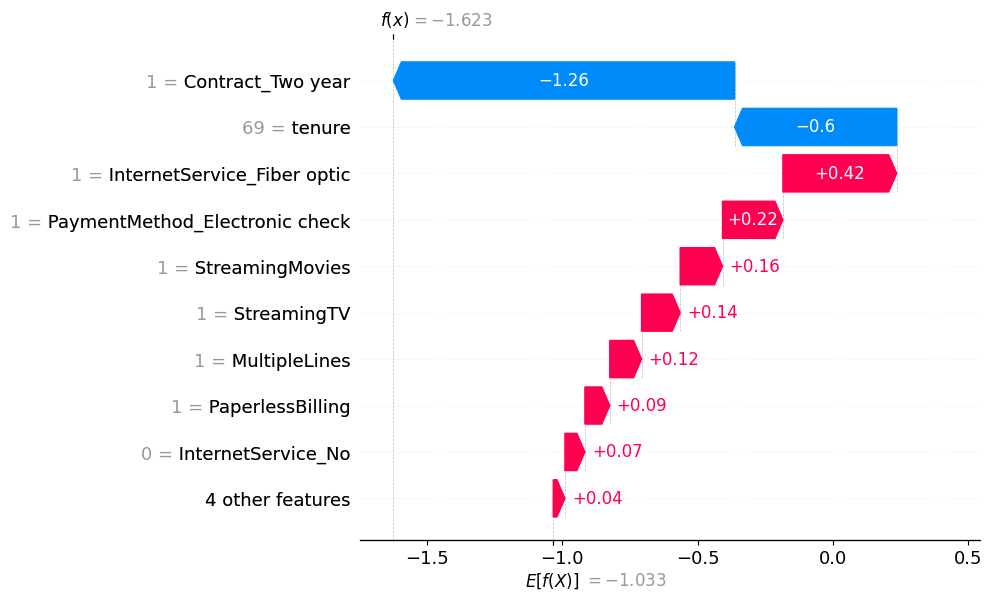

In [48]:
matches = X_test["customerID"].eq(selected_customer_id)
if not matches.any():
    raise ValueError(f"Customer ID '{selected_customer_id}' was not found in the test set.")

selected_idx = X_test.index[matches][0]
customer_row = X_test_xgb.loc[[selected_idx]]

churn_prob = xgb_model.predict_proba(customer_row)[0, 1]
pred_label = "Churn" if churn_prob >= xgb_threshold else "No Churn"
actual_label = "Churn" if y_test.loc[selected_idx] == 1 else "No Churn"

churn_drivers, protective_drivers, customer_shap = get_customer_shap_drivers(customer_row)

print(f"Customer ID: {selected_customer_id}")
print(f"Churn probability: {churn_prob:.3f}")
print(f"Threshold: {xgb_threshold:.2f}")
print(f"Predicted class: {pred_label}")
print(f"Actual class: {actual_label}")

print("\nTop churn-risk drivers:")
display(churn_drivers)

print("Top protective drivers:")
display(protective_drivers)

shap.plots.waterfall(customer_shap[0])

In [49]:
gemini_explanation = generate_customer_explanation(
    selected_customer_id,
    churn_prob,
    xgb_threshold,
    pred_label,
    churn_drivers,
    protective_drivers
)

print("Gemini explanation:\n")
print(gemini_explanation)

Gemini explanation:

Here is an explanation of the churn model prediction for Customer 6837-HAEVO based on the provided data:

### 1. Predicted Churn Risk Summary
Customer 6837-HAEVO has a predicted churn probability of **0.165**. Because this probability is below the established decision threshold of **0.34**, the model classifies this customer as **No Churn** (meaning they are predicted to stay).

### 2. Factors Pushing Toward Higher Churn Risk
The following factors provide the top positive contributions to the model's output, pushing the prediction toward a higher risk of churn:
* **InternetService_Fiber optic** (Value: 1.0): Contributes a value of +0.420097 to the model output.
* **PaymentMethod_Electronic check** (Value: 1.0): Contributes a value of +0.223077 to the model output.
* **StreamingMovies** (Value: 1.0): Contributes a value of +0.156238 to the model output.

### 3. Factors Pushing Toward Lower Churn Risk
The following factors provide the top negative contributions to th

## 17. Business-Facing Churn Risk Dashboard

A Shiny for Python application exposes the finalized XGBoost churn model through a customer-level interface.

For a selected Customer ID, the dashboard displays:
- Predicted churn probability
- Churn / No Churn classification using the finalized decision threshold
- Historical churn outcome for evaluation reference
- Customer-level SHAP waterfall explanation
- Top churn-risk and protective drivers

The deployment bundle also stores the feature metadata required for the what-if analysis in Section 18.

In [50]:
import pickle, numpy as np, pandas as pd

MULTICAT_FEATURES = ["InternetService", "Contract", "PaymentMethod"]

dummy_groups = {f: [c for c in final_features if c.startswith(f"{f}_")] for f in MULTICAT_FEATURES}
dummy_groups = {f: cols for f, cols in dummy_groups.items() if cols}

category_values = {f: X_train[f].dropna().astype(str).unique().tolist() for f in dummy_groups}

DERIVED_FEATURES = ["IsNewCustomer"]
all_dummy_cols = {c for cols in dummy_groups.values() for c in cols}

binary_features = [c for c in final_features if c not in all_dummy_cols and c not in DERIVED_FEATURES and c != "tenure"]
what_if_features = ["tenure"] + list(dummy_groups.keys()) + binary_features

deployment_bundle = {
    "model": xgb_model,
    "threshold": xgb_threshold,
    "final_features": final_features,
    "dummy_groups": dummy_groups,
    "category_values": category_values,
    "binary_features": binary_features,
    "what_if_features": what_if_features,
    "tenure_max": int(X_train["tenure"].max())
}

with open("churn_model_bundle.pkl", "wb") as f:
    pickle.dump(deployment_bundle, f)

demo_customer_data = pd.concat([
    X_test[["customerID"]].reset_index(drop=True),
    X_test_xgb.reset_index(drop=True),
    y_test.reset_index(drop=True).rename("Actual_Churn")
], axis=1)

demo_customer_data.to_csv("demo_customer_data.csv", index=False)

print("Deployment files created.")
print("What-if controls:", what_if_features)

Deployment files created.
What-if controls: ['tenure', 'InternetService', 'Contract', 'PaymentMethod', 'SeniorCitizen', 'MultipleLines', 'OnlineSecurity', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']


## 18. Interactive What-If Scenario Analysis

The dashboard is extended with customer-level what-if analysis.

For a selected customer, one business-facing input is varied while unrelated model inputs are held constant. Each hypothetical customer is then re-scored using the same finalized XGBoost model.

Implementation rules:
- Dummy-encoded variables are modified as mutually exclusive groups.
- Scenario controls are derived from the finalized model feature schema.
- Categories that collapse to the same retained model state are treated as one scenario.
- `IsNewCustomer` is not varied independently because it is derived from `tenure`.
- Whenever `tenure` changes, `IsNewCustomer` is recomputed using the original rule: `IsNewCustomer = 1` when `tenure <= 6`, otherwise `0`.
- What-if results represent model sensitivity to hypothetical inputs and should not be interpreted as causal effects.

In [51]:
def apply_scenario(customer_x, feature_name, value):
    scenario = customer_x.copy()

    if feature_name == "tenure":
        tenure_value = float(value)
        scenario.loc[:, "tenure"] = tenure_value
        if "IsNewCustomer" in final_features:
            scenario.loc[:, "IsNewCustomer"] = int(tenure_value <= 6)
        return scenario

    if feature_name in dummy_groups:
        group_cols = dummy_groups[feature_name]
        scenario.loc[:, group_cols] = 0
        expected_col = f"{feature_name}_{value}"
        if expected_col in group_cols:
            scenario.loc[:, expected_col] = 1
        return scenario

    if feature_name in binary_features:
        scenario.loc[:, feature_name] = int(value)
        return scenario

    raise ValueError(f"Unsupported what-if feature: {feature_name}")


def get_sweep_values(feature_name):
    if feature_name == "tenure":
        max_tenure = int(X_train["tenure"].max())
        values = np.arange(0, max_tenure + 1, 3)
        if max_tenure not in values:
            values = np.append(values, max_tenure)
        return values.tolist()

    if feature_name in dummy_groups:
        states = {}
        for value in category_values[feature_name]:
            expected_col = f"{feature_name}_{value}"
            state = expected_col if expected_col in dummy_groups[feature_name] else "__all_zero__"
            states.setdefault(state, []).append(value)
        return list(states.values())

    if feature_name in binary_features:
        return [[0], [1]]

    raise ValueError(f"No sweep rule for {feature_name}")


def what_if_sweep(customer_x, feature_name):
    rows = []

    for values in get_sweep_values(feature_name):
        if feature_name == "tenure":
            scenario_value = values
            display_label = str(int(values))
        else:
            scenario_value = values[0]
            display_label = str(values[0]) if len(values) == 1 else "Other / reference categories"

        scenario = apply_scenario(customer_x, feature_name, scenario_value)
        scenario = scenario[final_features].astype(float)
        probability = xgb_model.predict_proba(scenario)[0, 1]

        rows.append({
            "Scenario Value": display_label,
            "Predicted Churn Probability": probability
        })

    return pd.DataFrame(rows)

In [52]:
_test_customer = X_test_xgb.iloc[[0]].copy()

assert apply_scenario(_test_customer, "tenure", 6)["IsNewCustomer"].iloc[0] == 1
assert apply_scenario(_test_customer, "tenure", 9)["IsNewCustomer"].iloc[0] == 0

for value in category_values["Contract"]:
    s = apply_scenario(_test_customer, "Contract", value)
    assert s[dummy_groups["Contract"]].sum(axis=1).iloc[0] <= 1

print("✓ Scenario consistency checks passed.")

✓ Scenario consistency checks passed.


In [53]:
!pip install -q shiny shap

In [54]:
%%writefile churn_scoring.py

import pickle
import pandas as pd
import shap


class ChurnScorer:
    def __init__(self, model_path="churn_model_bundle.pkl"):
        with open(model_path, "rb") as f:
            bundle = pickle.load(f)

        self.model = bundle["model"]
        self.threshold = bundle["threshold"]
        self.final_features = bundle["final_features"]
        self.dummy_groups = bundle["dummy_groups"]
        self.category_values = bundle["category_values"]
        self.binary_features = bundle["binary_features"]
        self.what_if_features = bundle["what_if_features"]
        self.tenure_max = bundle["tenure_max"]

        self.explainer = shap.Explainer(self.model)

    def score(self, customer_x):
        customer_x = customer_x[self.final_features].astype(float)

        probability = self.model.predict_proba(customer_x)[0, 1]
        prediction = "Churn" if probability >= self.threshold else "No Churn"

        shap_values = self.explainer(customer_x)

        driver_table = pd.DataFrame({
            "Feature": self.final_features,
            "Customer Value": customer_x.iloc[0].values,
            "SHAP Impact": shap_values.values[0]
        })

        risk_drivers = (
            driver_table[driver_table["SHAP Impact"] > 0]
            .nlargest(3, "SHAP Impact")
            .reset_index(drop=True)
        )

        protective_drivers = (
            driver_table[driver_table["SHAP Impact"] < 0]
            .nsmallest(3, "SHAP Impact")
            .reset_index(drop=True)
        )

        return {
            "probability": probability,
            "prediction": prediction,
            "threshold": self.threshold,
            "shap_values": shap_values,
            "risk_drivers": risk_drivers,
            "protective_drivers": protective_drivers
        }

    def apply_scenario(self, customer_x, feature_name, value):
        scenario = customer_x.copy()

        if feature_name == "tenure":
            tenure_value = float(value)
            scenario.loc[:, "tenure"] = tenure_value

            if "IsNewCustomer" in self.final_features:
                scenario.loc[:, "IsNewCustomer"] = int(tenure_value <= 6)

            return scenario

        if feature_name in self.dummy_groups:
            group_cols = self.dummy_groups[feature_name]
            scenario.loc[:, group_cols] = 0

            expected_col = f"{feature_name}_{value}"

            if expected_col in group_cols:
                scenario.loc[:, expected_col] = 1

            return scenario

        if feature_name in self.binary_features:
            scenario.loc[:, feature_name] = int(value)
            return scenario

        raise ValueError(f"Unsupported feature: {feature_name}")

Overwriting churn_scoring.py


In [55]:
%%writefile app.py

from shiny import App, ui, render, reactive
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
import matplotlib as mpl

from churn_scoring import ChurnScorer

scorer = ChurnScorer("churn_model_bundle.pkl")

model = scorer.model
threshold = scorer.threshold
final_features = scorer.final_features
dummy_groups = scorer.dummy_groups
category_values = scorer.category_values
binary_features = scorer.binary_features
what_if_features = scorer.what_if_features
tenure_max = scorer.tenure_max

customers = pd.read_csv("demo_customer_data.csv")

FEATURE_LABELS = {
    "tenure": "Tenure",
    "InternetService": "Internet Service",
    "Contract": "Contract",
    "PaymentMethod": "Payment Method",
    "SeniorCitizen": "Senior Citizen",
    "MultipleLines": "Multiple Lines",
    "OnlineSecurity": "Online Security",
    "StreamingTV": "Streaming TV",
    "StreamingMovies": "Streaming Movies",
    "PaperlessBilling": "Paperless Billing"
}

feature_choices = {f: FEATURE_LABELS.get(f, f) for f in what_if_features}
default_customer = str(customers["customerID"].iloc[0])
default_feature = "Contract" if "Contract" in what_if_features else what_if_features[0]

COLOR_BG = "#F4F5F7"
COLOR_PANEL = "#FFFFFF"
COLOR_PANEL_ALT = "#F0F1F4"
COLOR_BORDER = "#E1E3E8"
COLOR_TEXT = "#1C2026"
COLOR_TEXT_MUTED = "#6B7280"
COLOR_RISK = "#C1512F"
COLOR_PROTECTIVE = "#2A8A73"
COLOR_PRIMARY = "#3D5A99"

mpl.rcParams.update({
    "figure.facecolor": COLOR_PANEL,
    "axes.facecolor": COLOR_PANEL,
    "savefig.facecolor": COLOR_PANEL,
    "text.color": COLOR_TEXT,
    "axes.edgecolor": COLOR_BORDER,
    "axes.labelcolor": COLOR_TEXT,
    "xtick.color": COLOR_TEXT_MUTED,
    "ytick.color": COLOR_TEXT_MUTED,
    "grid.color": COLOR_BORDER,
    "font.family": "sans-serif",
    "font.sans-serif": ["IBM Plex Sans", "Helvetica Neue", "Arial"],
    "font.size": 10.5,
})


def score_customer(customer_id):
    matched = customers[customers["customerID"].astype(str) == str(customer_id)]

    if matched.empty:
        return None

    customer_x = matched[final_features].astype(float)
    scoring_result = scorer.score(customer_x)

    actual = "Churn" if matched["Actual_Churn"].iloc[0] == 1 else "No Churn"

    return {
        "customer_x": customer_x,
        "probability": scoring_result["probability"],
        "prediction": scoring_result["prediction"],
        "actual": actual,
        "shap_values": scoring_result["shap_values"],
        "risk_drivers": scoring_result["risk_drivers"],
        "protective_drivers": scoring_result["protective_drivers"]
    }


def apply_scenario(customer_x, feature_name, value):
    return scorer.apply_scenario(customer_x, feature_name, value)


def get_sweep_values(feature_name):
    if feature_name == "tenure":
        values = np.arange(0, tenure_max + 1, 3)
        if tenure_max not in values:
            values = np.append(values, tenure_max)
        return values.tolist()

    if feature_name in dummy_groups:
        states = {}
        for value in category_values[feature_name]:
            expected_col = f"{feature_name}_{value}"
            state = expected_col if expected_col in dummy_groups[feature_name] else "__all_zero__"
            states.setdefault(state, []).append(value)
        return list(states.values())

    if feature_name in binary_features:
        return [[0], [1]]

    raise ValueError(f"No sweep rule for {feature_name}")


def what_if_sweep(customer_x, feature_name):
    rows = []

    for values in get_sweep_values(feature_name):
        if feature_name == "tenure":
            scenario_value = values
            display_label = str(int(values))
        else:
            scenario_value = values[0]
            display_label = str(values[0]) if len(values) == 1 else "Other / reference"

        scenario = apply_scenario(customer_x, feature_name, scenario_value)
        probability = model.predict_proba(scenario[final_features].astype(float))[0, 1]

        rows.append({
            "Scenario Value": display_label,
            "Scenario Raw Value": scenario_value,
            "Predicted Churn Probability": probability
        })

    return pd.DataFrame(rows)


def get_current_feature_value(customer_x, feature_name):
    row = customer_x.iloc[0]

    if feature_name == "tenure":
        return int(row["tenure"])

    if feature_name in binary_features:
        return "Yes" if int(row[feature_name]) == 1 else "No"

    if feature_name in dummy_groups:
        for value in category_values[feature_name]:
            col = f"{feature_name}_{value}"
            if col in dummy_groups[feature_name] and int(row[col]) == 1:
                return value

        refs = [v for v in category_values[feature_name] if f"{feature_name}_{v}" not in dummy_groups[feature_name]]
        return refs[0] if len(refs) == 1 else "Other / reference"

    return str(row.get(feature_name, ""))


def get_scenario_options(feature_name):
    if feature_name == "tenure":
        return None

    if feature_name in binary_features:
        return {"0": "No", "1": "Yes"}

    options = {}
    for values in get_sweep_values(feature_name):
        raw = values[0]
        label = str(raw) if len(values) == 1 else "Other / reference"
        options[str(raw)] = label

    return options


app_ui = ui.page_fluid(
    ui.tags.link(
        rel="stylesheet",
        href="https://fonts.googleapis.com/css2?family=IBM+Plex+Sans:wght@400;500;600;700&family=IBM+Plex+Mono:wght@400;500;600&display=swap"
    ),

    ui.tags.style("""
        :root {
            --bg: #F4F5F7;
            --panel: #FFFFFF;
            --panel-alt: #F0F1F4;
            --border: #E1E3E8;
            --text: #1C2026;
            --text-muted: #6B7280;
            --risk: #C1512F;
            --protective: #2A8A73;
            --primary: #3D5A99;
        }

        html, body {
            background: var(--bg);
            color: var(--text);
            font-family: 'IBM Plex Sans', 'Helvetica Neue', Arial, sans-serif;
        }

        .container-fluid { padding: 20px 28px 32px; max-width: 1400px; }
        .dashboard-header { margin-bottom: 20px; }

        .dashboard-title {
            margin: 0;
            font-size: 24px;
            font-weight: 600;
            letter-spacing: -0.01em;
            color: var(--text);
        }

        .dashboard-subtitle {
            margin: 4px 0 0;
            font-size: 13.5px;
            color: var(--text-muted);
        }

        .bslib-sidebar-layout > .sidebar,
        .sidebar {
            background: var(--panel-alt) !important;
            border-right: 1px solid var(--border) !important;
            padding: 18px 16px !important;
        }

        .sidebar-block { margin-bottom: 18px; }

        .sidebar-heading {
            font-weight: 600;
            font-size: 13px;
            color: var(--text);
            margin-bottom: 8px;
        }

        hr { border-color: var(--border); opacity: 1; margin: 14px 0; }
        .subtle { color: var(--text-muted); font-size: 12px; }

        label, .control-label, .shiny-input-container label {
            color: var(--text-muted) !important;
            font-size: 12.5px !important;
            font-weight: 500 !important;
            margin-bottom: 4px !important;
        }

        .form-control, .form-select,
        select.form-control, input.form-control {
            background: var(--panel-alt) !important;
            border: 1px solid var(--border) !important;
            color: var(--text) !important;
            border-radius: 6px !important;
        }

        .form-control:focus, .form-select:focus {
            border-color: var(--primary) !important;
            box-shadow: 0 0 0 2px rgba(61, 90, 153, 0.2) !important;
        }

        .btn-primary {
            background: var(--primary) !important;
            border-color: var(--primary) !important;
            color: #FFFFFF !important;
            font-weight: 600 !important;
            border-radius: 6px !important;
        }

        .btn-primary:hover { filter: brightness(1.08); }

        .irs--shiny .irs-bar, .irs--shiny .irs-single, .irs--shiny .irs-handle {
            background: var(--primary) !important;
            border-color: var(--primary) !important;
        }

        .irs--shiny .irs-line { background: var(--border) !important; }
        .irs--shiny .irs-grid-text { color: var(--text-muted) !important; }

        .irs--shiny .irs-min, .irs--shiny .irs-max {
            color: var(--text-muted) !important;
            background: transparent !important;
        }

        .section-title {
            font-size: 16px;
            font-weight: 600;
            color: var(--text);
            margin: 0 0 12px 0;
        }

        .summary-card {
            background: var(--panel);
            border: 1px solid var(--border);
            border-left: 3px solid var(--primary);
            border-radius: 8px;
            padding: 12px 16px;
            height: 78px;
        }

        .summary-label {
            font-size: 11.5px;
            color: var(--text-muted);
            margin-bottom: 4px;
        }

        .summary-value {
            font-family: 'IBM Plex Mono', monospace;
            font-size: 22px;
            font-weight: 600;
            color: var(--text);
        }

        .panel-card {
            background: var(--panel);
            border: 1px solid var(--border);
            border-radius: 8px;
            padding: 14px 16px;
        }

        .equal-height-row > .row { align-items: stretch; }
        .equal-height-row .panel-card { height: 100%; }

        .driver-panel {
            display: flex;
            flex-direction: column;
            justify-content: flex-start;
            gap: 28px;
        }

        .driver-section {
            width: 100%;
            overflow-x: auto;
        }

        .driver-table {
            width: 100%;
            table-layout: fixed;
            border-collapse: collapse;
            font-size: 12px;
        }

        .driver-table col.col-feature { width: 54%; }
        .driver-table col.col-value { width: 21%; }
        .driver-table col.col-shap { width: 25%; }

        .driver-table th {
            font-weight: 600;
            font-size: 10.5px;
            letter-spacing: 0.02em;
            color: var(--text-muted);
            text-align: left;
            padding: 4px 4px 6px;
            border-bottom: 1px solid var(--border);
        }

        .driver-table td {
            padding: 6px 4px;
            border-bottom: 1px solid var(--border);
            color: var(--text);
            font-family: 'IBM Plex Mono', monospace;
            font-size: 11px;
            vertical-align: top;
            overflow: hidden;
            text-overflow: ellipsis;
            white-space: nowrap;
        }

        .driver-table td:first-child {
            font-family: 'IBM Plex Sans', sans-serif;
            font-size: 12px;
            white-space: normal;
            word-break: break-word;
        }

        .driver-table tr:last-child td { border-bottom: none; }

        .shap-pill {
            display: inline-block;
            padding: 1px 6px;
            border-radius: 10px;
            font-size: 10.5px;
            white-space: nowrap;
        }

        .shap-pill.risk {
            background: rgba(221, 122, 82, 0.18);
            color: var(--risk);
        }

        .shap-pill.protective {
            background: rgba(79, 168, 143, 0.18);
            color: var(--protective);
        }

        .scenario-delta {
            font-family: 'IBM Plex Mono', monospace;
            font-size: 26px;
            font-weight: 600;
            margin: 10px 0;
        }
    """),

    ui.div(
        ui.h2("Customer Churn Risk Dashboard", class_="dashboard-title"),
        ui.p(
            "Score an individual customer, review what is driving the prediction, and test hypothetical changes.",
            class_="dashboard-subtitle"
        ),
        class_="dashboard-header"
    ),

    ui.layout_sidebar(
        ui.sidebar(
            ui.div(
                ui.div("Customer selection", class_="sidebar-heading"),
                ui.input_text("customer_id", "Customer ID", value=default_customer),
                ui.input_action_button("analyze", "Analyze customer", class_="btn-primary w-100"),
                class_="sidebar-block"
            ),

            ui.hr(),

            ui.div(
                ui.div("What-if controls", class_="sidebar-heading"),
                ui.input_select("feature", "Feature", choices=feature_choices, selected=default_feature),
                ui.output_ui("current_value_ui"),
                ui.output_ui("scenario_input"),
                class_="sidebar-block"
            ),

            ui.hr(),

            ui.div(
                ui.div("Model information", class_="sidebar-heading"),
                ui.div("Decision threshold", class_="summary-label"),
                ui.div(
                    f"{threshold:.0%}",
                    style="font-family:'IBM Plex Mono',monospace;font-size:20px;font-weight:600;"
                )
            ),

            width=300
        ),

        ui.div(
            ui.h3("Current customer risk", class_="section-title"),

            ui.layout_columns(
                ui.div(
                    ui.div("Predicted churn probability", class_="summary-label"),
                    ui.output_ui("probability_card"),
                    class_="summary-card"
                ),
                ui.output_ui("prediction_card_wrap"),
                ui.output_ui("actual_card_wrap"),
                col_widths=[4, 4, 4]
            ),

            ui.br(),

            ui.div(
                ui.layout_columns(
                    ui.div(
                        ui.div(
                            ui.div("Individual model explanation", class_="sidebar-heading"),
                            ui.output_plot(
                                "waterfall_plot",
                                height=f"{int(96 * (0.8 + 0.29 * len(final_features)))}px"
                            ),
                            class_="panel-card"
                        ),
                        style="height:100%;"
                    ),

                    ui.div(
                        ui.div(
                            ui.div(
                                ui.div("Top churn-risk drivers", class_="sidebar-heading"),
                                ui.output_ui("risk_table"),
                                class_="driver-section"
                            ),
                            ui.div(
                                ui.div("Top protective drivers", class_="sidebar-heading"),
                                ui.output_ui("protective_table"),
                                class_="driver-section"
                            ),
                            class_="panel-card driver-panel"
                        ),
                        style="height:100%;"
                    ),

                    col_widths=[9, 3]
                ),
                class_="equal-height-row"
            ),

            ui.hr(),

            ui.h3("What-if scenario analysis", class_="section-title"),

            ui.layout_columns(
                ui.div(
                    ui.output_ui("scenario_summary"),
                    class_="panel-card"
                ),

                ui.div(
                    ui.div("Feature sensitivity", class_="sidebar-heading"),
                    ui.output_plot("what_if_plot", height="260px"),
                    class_="panel-card"
                ),

                col_widths=[4, 8]
            ),

            ui.p(
                ui.tags.em(
                    "What-if results describe model sensitivity under hypothetical inputs and do not imply causal effects."
                ),
                class_="subtle",
                style="margin-top:10px;"
            )
        )
    )
)


def server(input, output, session):

    @reactive.calc
    @reactive.event(input.analyze)
    def result():
        customer_id = input.customer_id().strip()
        return score_customer(customer_id) if customer_id else None


    @output
    @render.ui
    def current_value_ui():
        r = result()
        if r is None:
            return ui.div()

        feature = input.feature()
        value = get_current_feature_value(r["customer_x"], feature)

        if feature == "tenure":
            value = f"{value} months"

        return ui.div(
            ui.div("Current value", class_="summary-label"),
            ui.div(str(value), style="font-weight:600;margin-bottom:10px;")
        )


    @output
    @render.ui
    def scenario_input():
        feature = input.feature()

        if feature == "tenure":
            return ui.input_slider(
                "scenario_value",
                "Scenario tenure",
                min=0,
                max=tenure_max,
                value=min(24, tenure_max),
                step=1
            )

        options = get_scenario_options(feature)

        return ui.input_select(
            "scenario_value",
            "Scenario value",
            choices=options,
            selected=next(iter(options.keys()))
        )


    @reactive.calc
    def scenario_result():
        r = result()
        if r is None:
            return None

        feature = input.feature()
        raw = input.scenario_value()

        if feature == "tenure":
            scenario_value = float(raw)
        elif feature in binary_features:
            scenario_value = int(raw)
        else:
            scenario_value = raw

        scenario_x = apply_scenario(r["customer_x"], feature, scenario_value)
        scenario_x = scenario_x[final_features].astype(float)

        probability = model.predict_proba(scenario_x)[0, 1]
        prediction = "Churn" if probability >= threshold else "No Churn"

        return {
            "feature": feature,
            "scenario_value": scenario_value,
            "probability": probability,
            "prediction": prediction
        }


    @output
    @render.ui
    def probability_card():
        r = result()
        return ui.div("—", class_="summary-value") if r is None else ui.div(
            f"{r['probability']:.1%}",
            class_="summary-value"
        )


    @output
    @render.ui
    def prediction_card_wrap():
        r = result()
        accent = "var(--border)"
        value = "—"

        if r is not None:
            accent = "var(--risk)" if r["prediction"] == "Churn" else "var(--protective)"
            value = r["prediction"]

        return ui.div(
            ui.div("Model prediction", class_="summary-label"),
            ui.div(value, class_="summary-value"),
            class_="summary-card",
            style=f"border-left-color:{accent};"
        )


    @output
    @render.ui
    def actual_card_wrap():
        r = result()
        accent = "var(--border)"
        value = "—"

        if r is not None:
            accent = "var(--risk)" if r["actual"] == "Churn" else "var(--protective)"
            value = r["actual"]

        return ui.div(
            ui.div("Historical outcome", class_="summary-label"),
            ui.div(value, class_="summary-value"),
            class_="summary-card",
            style=f"border-left-color:{accent};"
        )


    @output
    @render.plot
    def waterfall_plot():
        r = result()
        if r is None:
            return

        fig = plt.figure(figsize=(12, 0.8 + 0.29 * len(final_features)))

        shap.plots.waterfall(
            r["shap_values"][0],
            max_display=len(final_features),
            show=False
        )

        fig = plt.gcf()
        ax = plt.gca()
        ax.margins(y=0.01)

        fig.patch.set_facecolor(COLOR_PANEL)
        ax.set_facecolor(COLOR_PANEL)

        plt.subplots_adjust(left=0.31, right=0.97, top=0.95, bottom=0.06)

        return fig


    @output
    @render.ui
    def risk_table():
        r = result()
        if r is None:
            return ui.div()

        t = r["risk_drivers"].copy()

        rows = [
            ui.tags.tr(
                ui.tags.td(str(row["Feature"])),
                ui.tags.td(f"{row['Customer Value']:.2f}"),
                ui.tags.td(
                    ui.tags.span(
                        f"+{row['SHAP Impact']:.2f}",
                        class_="shap-pill risk"
                    )
                )
            )
            for _, row in t.iterrows()
        ]

        return ui.tags.table(
            ui.tags.colgroup(
                ui.tags.col(class_="col-feature"),
                ui.tags.col(class_="col-value"),
                ui.tags.col(class_="col-shap"),
            ),
            ui.tags.thead(
                ui.tags.tr(
                    ui.tags.th("Feature"),
                    ui.tags.th("Value"),
                    ui.tags.th("SHAP")
                )
            ),
            ui.tags.tbody(*rows),
            class_="driver-table"
        )


    @output
    @render.ui
    def protective_table():
        r = result()
        if r is None:
            return ui.div()

        t = r["protective_drivers"].copy()

        rows = [
            ui.tags.tr(
                ui.tags.td(str(row["Feature"])),
                ui.tags.td(f"{row['Customer Value']:.2f}"),
                ui.tags.td(
                    ui.tags.span(
                        f"{row['SHAP Impact']:.2f}",
                        class_="shap-pill protective"
                    )
                )
            )
            for _, row in t.iterrows()
        ]

        return ui.tags.table(
            ui.tags.colgroup(
                ui.tags.col(class_="col-feature"),
                ui.tags.col(class_="col-value"),
                ui.tags.col(class_="col-shap"),
            ),
            ui.tags.thead(
                ui.tags.tr(
                    ui.tags.th("Feature"),
                    ui.tags.th("Value"),
                    ui.tags.th("SHAP")
                )
            ),
            ui.tags.tbody(*rows),
            class_="driver-table"
        )


    @output
    @render.ui
    def scenario_summary():
        r = result()
        s = scenario_result()

        if r is None or s is None:
            return ui.p("Analyze a customer to begin.", class_="subtle")

        feature = s["feature"]
        current_value = get_current_feature_value(r["customer_x"], feature)

        if feature == "tenure":
            current_display = f"{int(current_value)} months"
            scenario_display = f"{int(float(s['scenario_value']))} months"
        elif feature in binary_features:
            current_display = current_value
            scenario_display = "Yes" if int(s["scenario_value"]) == 1 else "No"
        else:
            current_display = current_value
            scenario_display = str(s["scenario_value"])

        delta = (s["probability"] - r["probability"]) * 100
        delta_color = (
            "var(--risk)"
            if delta > 0
            else "var(--protective)"
            if delta < 0
            else "var(--text-muted)"
        )

        return ui.div(
            ui.div("Current to scenario", class_="sidebar-heading"),
            ui.p(
                ui.strong(FEATURE_LABELS.get(feature, feature) + ": "),
                f"{current_display} \u2192 {scenario_display}"
            ),
            ui.div(
                f"{r['probability']:.1%} \u2192 {s['probability']:.1%}",
                class_="scenario-delta"
            ),
            ui.p(f"{r['prediction']} \u2192 {s['prediction']}"),
            ui.p(
                ui.strong("Change: "),
                ui.span(
                    f"{delta:+.1f} pp",
                    style=f"color:{delta_color};font-weight:600;"
                )
            )
        )


    @output
    @render.plot
    def what_if_plot():
        r = result()
        s = scenario_result()

        if r is None or s is None:
            return

        feature = s["feature"]
        sweep = what_if_sweep(r["customer_x"], feature)

        fig, ax = plt.subplots(figsize=(9, 3.8))
        fig.patch.set_facecolor(COLOR_PANEL)
        ax.set_facecolor(COLOR_PANEL)

        if feature == "tenure":
            x = pd.to_numeric(sweep["Scenario Value"])
            y = sweep["Predicted Churn Probability"]

            ax.plot(x, y, marker="o", markersize=4, linewidth=2, color=COLOR_PRIMARY)

            current_tenure = float(r["customer_x"]["tenure"].iloc[0])
            scenario_tenure = float(s["scenario_value"])

            ax.axvline(
                current_tenure,
                linestyle=":",
                color=COLOR_TEXT_MUTED,
                label=f"Current ({current_tenure:.0f})"
            )

            ax.axvline(
                scenario_tenure,
                linestyle="-.",
                color=COLOR_PRIMARY,
                label=f"Scenario ({scenario_tenure:.0f})"
            )

            ax.set_xlabel("Tenure (months)")

        else:
            labels = sweep["Scenario Value"].tolist()
            probs = sweep["Predicted Churn Probability"].tolist()

            current_value = get_current_feature_value(r["customer_x"], feature)

            scenario_label = (
                "Yes" if int(s["scenario_value"]) == 1 else "No"
            ) if feature in binary_features else str(s["scenario_value"])

            bar_colors = []

            for label in labels:
                if str(label) == str(scenario_label):
                    bar_colors.append(COLOR_PRIMARY)
                elif str(label) == str(current_value):
                    bar_colors.append(COLOR_TEXT_MUTED)
                else:
                    bar_colors.append(COLOR_BORDER)

            bars = ax.bar(labels, probs, color=bar_colors)

            for bar, label in zip(bars, labels):
                notes = []

                if str(label) == str(current_value):
                    notes.append("Current")

                if str(label) == str(scenario_label):
                    notes.append("Scenario")

                if notes:
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + 0.02,
                        " / ".join(notes),
                        ha="center",
                        va="bottom",
                        fontsize=9,
                        color=COLOR_TEXT
                    )

            ax.set_xlabel(FEATURE_LABELS.get(feature, feature))
            ax.tick_params(axis="x", rotation=12)

        ax.axhline(
            threshold,
            linestyle="--",
            color=COLOR_RISK,
            label=f"Threshold ({threshold:.0%})"
        )

        ax.set_ylim(0, 1)
        ax.set_ylabel("Predicted churn probability")
        ax.set_title(
            f"What-if: {FEATURE_LABELS.get(feature, feature)}",
            fontsize=12,
            color=COLOR_TEXT
        )

        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.25)

        legend = ax.legend(
            fontsize=8,
            facecolor=COLOR_PANEL,
            edgecolor=COLOR_BORDER
        )

        for text in legend.get_texts():
            text.set_color(COLOR_TEXT)

        plt.tight_layout()
        return fig


app = App(app_ui, server)

Overwriting app.py


In [56]:
!pkill -f "shiny run" || true
!nohup shiny run app.py --host 0.0.0.0 --port 8000 > /tmp/shiny.log 2>&1 &

^C


In [57]:
import time
from google.colab import output

time.sleep(3)
output.serve_kernel_port_as_window(8000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

## 19. Summary of Results

This section consolidates the final results from feature selection, model comparison, threshold selection, validation, and customer-level interpretation.

In [58]:
# Pull final validation metrics directly from the model confirmation table
logit_val_auc = model_confirmation.loc[
    (model_confirmation["Dataset"] == "Validation") &
    (model_confirmation["Model"] == "Logistic Regression"),
    "AUC"
].iloc[0]

xgb_val_auc = model_confirmation.loc[
    (model_confirmation["Dataset"] == "Validation") &
    (model_confirmation["Model"] == "XGBoost"),
    "AUC"
].iloc[0]

summary_results = pd.DataFrame({
    "Metric": [
        "Final predictor count",
        "Logistic Regression Train ROC-AUC",
        "Logistic Regression Test ROC-AUC",
        "Logistic Regression Validation ROC-AUC",
        "XGBoost Train ROC-AUC",
        "XGBoost Test ROC-AUC",
        "XGBoost Validation ROC-AUC",
        "Logistic Regression threshold",
        "XGBoost threshold"
    ],
    "Result": [
        len(final_features),
        auc_train,
        auc_test,
        logit_val_auc,
        xgb_train_auc,
        xgb_test_auc,
        xgb_val_auc,
        logit_threshold,
        xgb_threshold
    ]
})

summary_results["Result"] = summary_results["Result"].map(
    lambda x: f"{x:.4f}" if isinstance(x, (float, np.floating)) else str(x)
)

display(summary_results)

,Metric,Result
0,Final predictor count,13.0000
1,Logistic Regression Train ROC-AUC,0.8491
2,Logistic Regression Test ROC-AUC,0.8438
3,Logistic Regression Validation ROC-AUC,0.8566
4,XGBoost Train ROC-AUC,0.8604
5,XGBoost Test ROC-AUC,0.8460
6,XGBoost Validation ROC-AUC,0.8561
7,Logistic Regression threshold,0.3200
8,XGBoost threshold,0.3400


## 20. Additional Recommended Next Steps

The current notebook demonstrates an end-to-end churn modeling workflow, from feature selection and model validation to customer-level interpretation and interactive scenario analysis. If the model were moved toward production use, the following steps would be recommended:

1. **Validate on newer production data**  
   Re-evaluate discrimination, calibration, and classification performance on more recent customer cohorts to confirm that model performance remains stable over time.

2. **Monitor feature and prediction drift**  
   Track changes in the distributions of important predictors and predicted churn probabilities to identify when model retraining or review may be needed.

3. **Align the decision threshold with business capacity and cost**  
   The current threshold is selected statistically using F1 score. In production, the threshold should also reflect retention-team capacity, intervention cost, and the relative cost of false positives versus missed churners.

4. **Validate retention actions experimentally**  
   SHAP values and what-if results describe predictive relationships, not causal effects. Retention strategies should therefore be evaluated through controlled experiments or A/B testing before being treated as effective interventions.

5. **Integrate the scoring workflow with production systems**  
   The current Shiny application demonstrates customer-level scoring and explanation. A production implementation could connect the scoring layer to live customer data and expose predictions through an application or API.

## 21. Deployment

The final churn model is packaged into reusable deployment artifacts so that scoring can run independently from the training notebook and be reused by the standalone Shiny application.

The deployment package includes:
- `churn_model_bundle.pkl` — trained model and required metadata
- `churn_scoring.py` — reusable scoring and what-if scenario logic
- `app.py` — standalone Shiny user interface
- `demo_customer_data.csv` — sample customer data used by the application

In [59]:
import os

deployment_files = [
    "churn_model_bundle.pkl",
    "churn_scoring.py",
    "app.py",
    "demo_customer_data.csv"
]

for file in deployment_files:
    status = "Ready" if os.path.exists(file) else "Missing"
    print(f"{file}: {status}")

churn_model_bundle.pkl: Ready
churn_scoring.py: Ready
app.py: Ready
demo_customer_data.csv: Ready


In [60]:
import pandas as pd
from churn_scoring import ChurnScorer

scorer = ChurnScorer("churn_model_bundle.pkl")

customers = pd.read_csv("demo_customer_data.csv")
sample_customer = customers.iloc[[0]][scorer.final_features]

test_result = scorer.score(sample_customer)

print("Probability:", round(test_result["probability"], 4))
print("Prediction:", test_result["prediction"])
print("Threshold:", test_result["threshold"])

assert 0 <= test_result["probability"] <= 1
assert test_result["prediction"] in ["Churn", "No Churn"]

print("Deployment smoke test passed.")

Probability: 0.1648
Prediction: No Churn
Threshold: 0.34
Deployment smoke test passed.
